In [57]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [58]:
df=pd.read_csv('Dataset.csv')

In [59]:
df['sales'] = pd.to_numeric(df['sales'].astype(str).str.replace(',', ''), errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')
df.fillna(0, inplace=True)

In [65]:
df['is_profitable'] = np.where(df['profit'] > 0, 1, 0)

categorical_cols = ['ship_mode', 'segment', 'market', 'region', 'category', 'sub_category', 'order_priority']
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

drop_cols = ['order_id', 'order_date', 'ship_date', 'customer_name', 'state', 'country',
             'product_id', 'product_name', 'profit', 'is_profitable']

X = df.drop(columns=drop_cols)
y = df['is_profitable']

print("Features selected for model:", X.columns.tolist())

Features selected for model: ['ship_mode', 'segment', 'market', 'region', 'category', 'sub_category', 'sales', 'quantity', 'discount', 'shipping_cost', 'order_priority', 'year']


In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [67]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [68]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy  : 0.9247
Precision : 0.9301
Recall    : 0.9726
F1-Score  : 0.9509

Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.78      0.84      2575
           1       0.93      0.97      0.95      7690

    accuracy                           0.92     10265
   macro avg       0.92      0.88      0.89     10265
weighted avg       0.92      0.92      0.92     10265



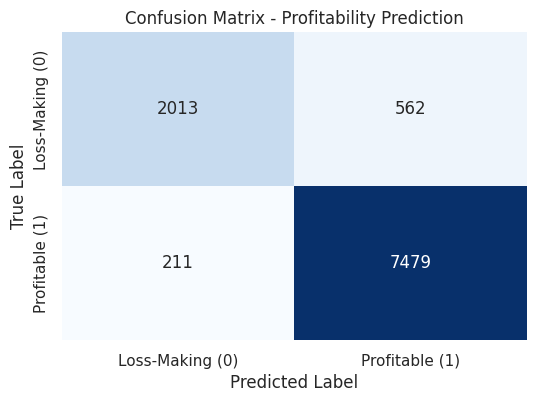

In [69]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Loss-Making (0)', 'Profitable (1)'],
            yticklabels=['Loss-Making (0)', 'Profitable (1)'])
plt.title('Confusion Matrix - Profitability Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()